# PH 4050  Computational Electrodynamics - Lab 6 - Pamudu Amarasinghe

# Simulation of the electromagnetic fields inside a brick-shaped cavity with perfectly conducting walls.

# 2) Initiations the parameters

In [1]:
import numpy as np

Lx = 0.05
Ly = 0.04
Lz = 0.03

h = 0.005

nx = int(round(Lx / h))
ny = int(round(Ly / h))
nz = int(round(Lz / h))

dx = Lx / nx
dy = Ly / ny    
dz = Lz / nz

#inverse dimension
idx = 1.0 / dx
idy = 1.0 / dy
idz = 1.0 / dz

nt = 2**13

#stability condition
c = 3e8
inv_ = np.array([idx, idy, idz])
dt = (1.0/c)*(1.0/np.linalg.norm(inv_))

t_total = nt * dt

print("Num cells: ", nx,ny,nz)
print("Total time: ", t_total)
print("Time step: ", dt)
print("dx, dy, dz: ", dx, dy, dz)




Num cells:  10 8 6
Total time:  7.882755675335691e-08
Time step:  9.622504486493764e-12
dx, dy, dz:  0.005 0.005 0.005


# 3) The field matrices

In [2]:
#Electric field
Ex = np.zeros((nx, ny +1, nz +1))
Ey = np.zeros((nx +1, ny, nz +1))
Ez = np.zeros((nx +1, ny +1, nz))

#Mag Feild
Hx = np.zeros((nx +1, ny, nz))
Hy = np.zeros((nx, ny +1, nz))
Hz = np.zeros((nx, ny, nz +1))



# 4) Time Signal for 3D feild

In [3]:
time_= np.zeros((nt, 3))

# 5) 
Initiate the electric field components with noise using random numbers except on the
boundaries. Subtract 0.5 from all the numbers to ensure the random values are centered
around zero, with equal probability for positive and negative values.

In [4]:
Ex[:, 1:-1, 1:-1] = np.random.rand(nx,ny -1,nz -1) - 0.5
Ey[1:-1,:,1:-1] = np.random.rand(nx -1, ny,nz -1) - 0.5
Ez[1:-1, 1:-1, :] = np.random.rand(nx -1, ny - 1,nz) - 0.5

# 6) 7) 8) updating feilds and time and applying FFT

In [ ]:
eps0 = 8.854e-12
mu0 = 1.2566e-6

for n in range(nt):
    #magnetic field update
    Hx += (dt / mu0) * (np.diff(Ey, axis=2) * idz - np.diff(Ez, axis=1) * idy)
    Hy += (dt / mu0) * (np.diff(Ez, axis=0) * idx - np.diff(Ex, axis=2) * idz)
    Hz += (dt / mu0) * (np.diff(Ex, axis=1) * idy - np.diff(Ey, axis=0) * idx)

    #electric field update
    Ex[:, 1:-1, 1:-1] += (dt / eps0) * (np.diff(Hz[:, :, 1:-1], axis=1) * idy - np.diff(Hy[:, 1:-1, :], axis=2) * idz)
    Ey[1:-1, :, 1:-1] += (dt / eps0) * (np.diff(Hx[1:-1, :, :], axis=2) * idz - np.diff(Hz[:, :, 1:-1], axis=0) * idx)
    Ez[1:-1, 1:-1, :] += (dt / eps0) * (np.diff(Hy[:, 1:-1, :], axis=0) * idx - np.diff(Hx[1:-1, :, :], axis=1) * idy)

    time_[n, 0] = Ex[3, 3, 3]
    time_[n, 1] = Ey[3, 3, 3]
    time_[n, 2] = Ez[3, 3, 3]


fft_signals = np.abs(np.fft.fft(time_, axis=0))

print(fft_signals)




[[5.87838357e+02 3.61433758e+02 1.22746412e+03]
 [4.65659902e-01 2.81005620e-02 2.83015016e-01]
 [4.65661807e-01 2.81399455e-02 2.83014325e-01]
 ...
 [4.65664982e-01 2.82054678e-02 2.83013174e-01]
 [4.65661807e-01 2.81399455e-02 2.83014325e-01]
 [4.65659902e-01 2.81005620e-02 2.83015016e-01]]
[0.00000000e+00 1.26859190e+07 2.53718380e+07 ... 1.03884991e+11
 1.03897677e+11 1.03910363e+11]


# 9)

In [ ]:
# Frequency Vector
total_time = nt * dt
m = np.arange(nt)
fm = (1.0 / t_total) * m

print(fm)

[[5.87838357e+02 3.61433758e+02 1.22746412e+03]
 [4.65659902e-01 2.81005620e-02 2.83015016e-01]
 [4.65661807e-01 2.81399455e-02 2.83014325e-01]
 ...
 [4.65664982e-01 2.82054678e-02 2.83013174e-01]
 [4.65661807e-01 2.81399455e-02 2.83014325e-01]
 [4.65659902e-01 2.81005620e-02 2.83015016e-01]]
[0.00000000e+00 1.26859190e+07 2.53718380e+07 ... 1.03884991e+11
 1.03897677e+11 1.03910363e+11]


# 10)

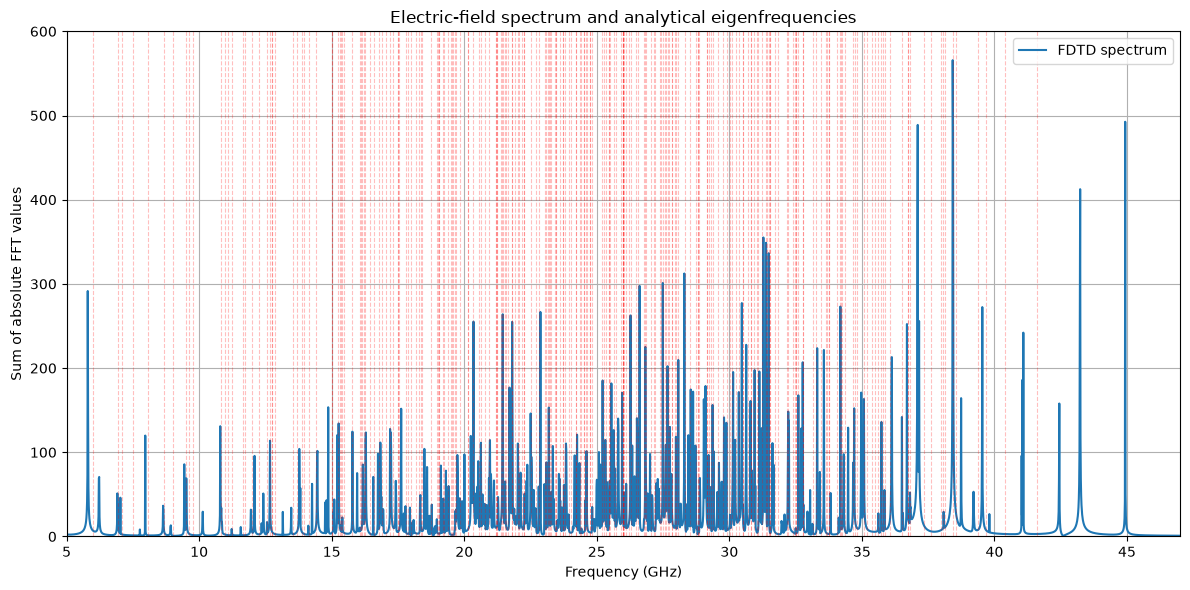

In [ ]:
#absolute value of the fft signals
from matplotlib.pylab import positive


Ex_fft = np.abs(np.fft.fft(time_[:, 0]))
Ey_fft = np.abs(np.fft.fft(time_[:, 1]))
Ez_fft = np.abs(np.fft.fft(time_[:, 2]))

E_fft = np.sqrt(Ex_fft**2 + Ey_fft**2 + Ez_fft**2)

Freq = np.fft.fftfreq(nt, dt)
Positive_Freq = Freq >= 0

Eigenfreq = []


max_index = 6

# TE modes: p = 0, with m or n (or both) nonzero
for m in range(max_index + 1):
    for n in range(max_index + 1):
        p = 0

        if m == 0 and n == 0:
            continue

        f = (c / 2) * np.sqrt(
            (m / Lx)**2 + (n / Ly)**2 + (p / Lz)**2
        )

        Eigenfreq.append((f, f"TE({m},{n},{p})"))

# TM modes: all three indices nonzero
for m in range(1, max_index + 1):
    for n in range(1, max_index + 1):
        for p in range(1, max_index + 1):

            f = (c / 2) * np.sqrt(
                (m / Lx)**2 + (n / Ly)**2 + (p / Lz)**2
            )

            Eigenfreq.append((f, f"TM({m},{n},{p})"))

# Plot the numerical spectrum in GHz

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(Freq[Positive_Freq] / 1e9,E_fft[Positive_Freq],label="FDTD spectrum")

nyquist = 1.0 / (2 * dt)
shown = set()

for f, mode in Eigenfreq:
    if f <= nyquist and f not in shown:
        plt.axvline(f / 1e9,color="red",linestyle='--',alpha=0.25,linewidth=0.8)
        shown.add(f)

plt.xlabel("Frequency (GHz)")
plt.ylabel("Sum of absolute FFT values")
plt.title("Electric-field spectrum with Analytical Eigenfrequencies")
plt.xlim(5, 47)
plt.ylim(0, 600)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

